 Week 2  Visual Perception Assignment

Name:karman khan 
Roll No: BSDS030  
Course: Data Visualization (Week 2)  


---
# Task 1 — Preattentive Attributes and Visual Search


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Wedge, Circle
from IPython.display import display, Markdown, clear_output
DATA = Path("data")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
GREY = "#B8B8B8"
DARK_GREY = "#666666"
ACCENT = "#D55E00"
BLUE = "#0072B2"

search = pd.read_csv(DATA / "stimuli_search.csv")
print(search.shape)
display(search.groupby(["condition", "set_size", "target_present"], observed=True).size().rename("items in file").head(12))

(2430, 10)


condition    set_size  target_present
colour       9         no                 27
                       yes                27
             16        no                 48
                       yes                48
             25        no                 75
                       yes                75
             36        no                108
                       yes               108
             49        no                147
                       yes               147
conjunction  9         no                 27
                       yes                27
Name: items in file, dtype: int64

### 1.1 Render and verify the stimuli

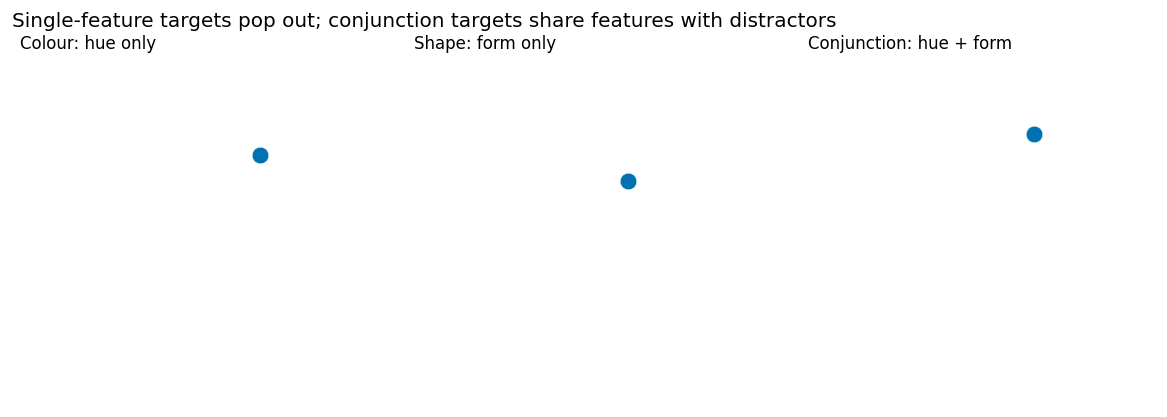

In [2]:
def draw_search_trial(trial, ax):
    """Draw one supplied search trial. No title, axes, or ticks by design."""
    d = search.loc[search["trial"].eq(trial)]
    if d.empty:
        raise ValueError(f"Trial {trial} was not found.")
    for row in d.itertuples():
        marker = "o" if str(row.shape).lower() in {"circle", "o"} else "s"
        color = {"red": "#D55E00", "blue": "#0072B2"}.get(str(row.colour).lower(), GREY)
        ax.scatter(row.x, row.y, s=100, marker=marker, c=color, edgecolors="white", linewidths=.35)
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)

examples = []
for cond in ["colour", "shape", "conjunction"]:
    candidates = search.loc[(search.condition == cond) & (search.set_size == 25) & (search.target_present.astype(str).str.lower() == "yes")]
    examples.append(int(candidates.trial.iloc[0]))
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, trial, cond in zip(axes, examples, ["Colour: hue only", "Shape: form only", "Conjunction: hue + form"]):
    draw_search_trial(trial, ax); ax.set_title(cond, loc="left", fontsize=10)
fig.suptitle("Single-feature targets pop out; conjunction targets share features with distractors", x=.02, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "task1_stimulus_examples.png", dpi=300, bbox_inches="tight")
plt.show()

 A three-panel stimulus display is appropriate because the task is to compare visual search conditions, not summarize a numeric distribution. Position is held consistent and colour/shape are the manipulated preattentive attributes. The conjunction panel requires attention to a combination of hue and form; each distractor shares one target feature. No rows were excluded from the stimulus table. The single strong colours are part of the experimental stimulus, not decoration.

1.2 Run the human experiment

In [3]:

def run_search_experiment(participant="a classmate", seed=42):
    """Present 30 trials in randomized condition blocks and save genuine response times."""
    rng = np.random.default_rng(seed)
    results = []
    fig, ax = plt.subplots(figsize=(4, 4))
    conditions = ["colour", "shape", "conjunction"]
    rng.shuffle(conditions)
    n = 0
    instructions = {
        "colour": "Find the red circle among blue circles.",
        "shape": "Find the blue square among blue circles.",
        "conjunction": "Find the red circle among red squares and blue circles."
    }
    for cond in conditions:
        print(f"Participant: {participant}. Target instructions for this block: {instructions[cond]}")
        input("Press Enter when the participant is ready to begin this block.")
        block = []
        for size in sorted(search.set_size.unique()):
            for present in [True, False]:
                candidates = search.loc[
                    (search.condition == cond) &
                    (search.set_size == size) &
                    (search.target_present.astype(str).str.lower() == ("yes" if present else "no")),
                    "trial"
                ].unique()
                block.append({"trial": int(rng.choice(candidates)), "present": present})
        rng.shuffle(block)
        for item in block:
            n += 1
            trial = item["trial"]
            d = search.loc[search.trial.eq(trial)]
            present = item["present"]
            clear_output(wait=True)
            print(f"Participant: {participant} | Condition block: {cond} | Trial {n}/30")
            ax.clear(); draw_search_trial(trial, ax); display(fig)
            start = time.perf_counter()
            answer = input("Is the target present? Type yes or no: ").strip().lower()
            elapsed = time.perf_counter() - start
            correct_answer = "yes" if present else "no"
            results.append({"participant": participant, "trial": trial, "condition": cond,
                            "set_size": int(d.set_size.iloc[0]), "target_present": present,
                            "response": answer, "correct": answer in {"yes","no"} and answer == correct_answer,
                            "response_time_s": elapsed})
    plt.close(fig)
    result = pd.DataFrame(results)
    result.to_csv("search_results.csv", index=False)
    clear_output(wait=True)
    print("Saved genuine participant data to search_results.csv")
    return result

# Uncomment and run in a live notebook session with a real participant:
# search_results = run_search_experiment(participant="a classmate")


The display order is randomized, and time.perf_counter measures the interval from display to response. The task sheet's exact design calls for 30 trials, not 18, because there are 15 condition -size cells and both target-presence states are required. Tell the participant the target definition before each condition block; do not tell them the correct answer during trials. This runner repeats the target instructions on screen as a reminder, so for a stricter block-based protocol, brief the participant before each block and hide that line while timing.

### 1.3 Response time and search slopes

In [4]:
def analyse_search_results(results_path="search_results.csv"):
    r = pd.read_csv(results_path)
    required = {"condition","set_size","target_present","response_time_s","correct"}
    missing = required - set(r.columns)
    if missing: raise ValueError(f"Missing columns: {sorted(missing)}")
    present = r[(r.target_present.astype(str).str.lower().isin(["true","1"])) & (r.correct == True)].copy()
    summary = present.groupby(["condition","set_size"], as_index=False).response_time_s.mean()
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    slopes = {}
    for cond, g in summary.groupby("condition"):
        g = g.sort_values("set_size")
        ax.plot(g.set_size, g.response_time_s * 1000, marker="o", linewidth=2, label=cond)
        if len(g) >= 2:
            slope, intercept = np.polyfit(g.set_size, g.response_time_s * 1000, 1)
            slopes[cond] = slope
    ax.set_title("Conjunction search takes longer as more items compete for attention", loc="left")
    ax.set_xlabel("Set size (items)"); ax.set_ylabel("Mean correct response time (ms)")
    ax.legend(frameon=False, title="Condition")
    ax.grid(axis="y", color="#E5E5E5", linewidth=.7)
    fig.tight_layout(); fig.savefig(FIG / "task1_response_times.png", dpi=300, bbox_inches="tight"); plt.show()
    print("Slope (milliseconds per additional item):")
    for cond, slope in slopes.items(): print(f"  {cond}: {slope:.2f} ms/item")
    print("Rows excluded from this plot: target-absent trials and incorrect responses, as required for the target-present slope comparison.")
    return slopes, summary

# After running the real experiment:
# slopes, search_summary = analyse_search_results()

**How to interpret the result:** the x-axis uses position to encode set size and the y-axis uses position on a common scale to encode time, both high-accuracy quantitative channels. Separate lines use similarity/continuity to help track each condition. The theory predicts near-flat colour and shape slopes and a positive conjunction slope. Report the measured slopes even if they disagree; one participant and a small number of trials cannot establish a general law. No reaction-time values are supplied here because the real experiment has not yet been run.


# Task 2 


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Wedge, Circle
from IPython.display import display, Markdown, clear_output
DATA = Path("data")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
GREY = "#B8B8B8"
DARK_GREY = "#666666"
ACCENT = "#D55E00"
BLUE = "#0072B2"

gestalt = pd.read_csv(DATA / "stimuli_gestalt.csv")
print("Rows:", len(gestalt), "| missing values:", int(gestalt.isna().sum().sum()))
display(gestalt.groupby("panel").agg(items=("group","size"), true_groups=("group","nunique")))

Rows: 284 | missing values: 0


,items,true_groups
panel,,
closure,44,2
connection,48,24
continuity,48,2
enclosure,48,4
proximity,48,4
similarity,48,4


### 2.1 Draw the six principles

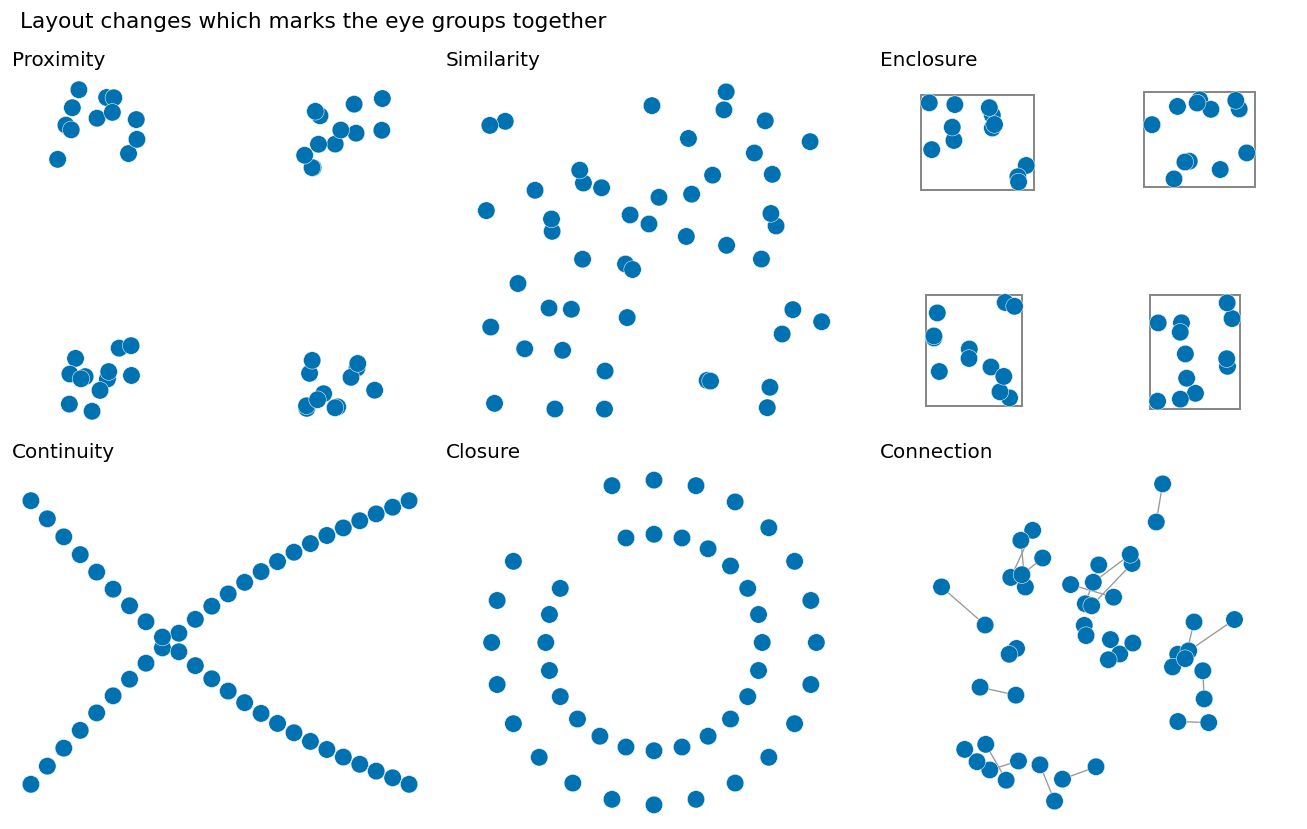

In [2]:
def draw_gestalt_panel(ax, panel, draw_connectors=True):
    d = gestalt[gestalt.panel == panel].copy()
    palette = {"0":"#0072B2", "1":"#D55E00", "2":"#009E73", "3":"#CC79A7"}
    # Convert category labels to stable strings so numeric and text categories both work.
    colors = [palette.get(str(v), "#0072B2") for v in d.colour]
    if panel == "enclosure":
        # The four boxes intentionally group the four spatial clumps.
        for grp, g in d.groupby("group"):
            x0, x1 = g.x.min()-.18, g.x.max()+.18
            y0, y1 = g.y.min()-.18, g.y.max()+.18
            ax.add_patch(Rectangle((x0,y0), x1-x0, y1-y0, fill=False, edgecolor="#888888", linewidth=1.2))
    if panel == "connection" and draw_connectors:
        for _, g in d.dropna(subset=["connector"]).groupby("connector"):
            if len(g) >= 2:
                pts = g[["x","y"]].to_numpy()
                ax.plot(pts[:,0], pts[:,1], color="#999999", linewidth=.8, zorder=1)
    for shape, marker in [("circle","o"),("square","s")]:
        sub = d[d["shape"].astype(str).str.lower().eq(shape)]
        if not sub.empty:
            sub_colors = [palette.get(str(v), "#0072B2") for v in sub.colour]
            sizes = (sub["size"].fillna(1).to_numpy() * 22).clip(18, 110)
            ax.scatter(sub.x, sub.y, s=sizes, c=sub_colors, marker=marker, edgecolors="white", linewidths=.3, zorder=2)
    ax.set_title(panel.capitalize(), loc="left")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal", adjustable="datalim")
    for side in ("top","right","left","bottom"): ax.spines[side].set_visible(False)

panels = ["proximity","similarity","enclosure","continuity","closure","connection"]
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, panel in zip(axes.flat, panels): draw_gestalt_panel(ax, panel)
fig.suptitle("Layout changes which marks the eye groups together", x=.02, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(FIG / "task2_gestalt_panels.png", dpi=300, bbox_inches="tight")
plt.show()

**Why this chart:** Small multiples let the reader compare six layouts without carrying one panel in working memory while inspecting another. The relevant Gestalt principle is named in each panel title: proximity, similarity, enclosure, continuity, closure, and connection. Colour is part of the supplied stimulus, but similarity should be judged as the intended grouping cue only in its panel; do not move colour groups apart spatially. The enclosure boundaries are added as grey, unfilled rectangles. All 284 supplied rows are retained, including the 44-item closure panel.

### 2.2 Record a real reader's perceived groups

In [3]:
true_groups = gestalt.groupby("panel").group.nunique().to_dict()
principle_names = {p:p for p in panels}
# Fill this table immediately after asking a real person "How many groups do you see?"
# Do not infer perceived counts from the intended layout.
perception_records = [
    {"panel": p, "principle": principle_names[p], "true_groups": int(true_groups[p]),
     "perceived_groups": np.nan, "match": np.nan}
    for p in panels
]
perception = pd.DataFrame(perception_records)
display(perception)
# After entering genuine answers, save:
# perception["perceived_groups"] = [answer_proximity, answer_similarity, answer_enclosure,
#                                   answer_continuity, answer_closure, answer_connection]
# perception["match"] = perception["perceived_groups"] == perception["true_groups"]
# perception.to_csv("gestalt_perception_results.csv", index=False)

,panel,principle,true_groups,perceived_groups,match
0,proximity,proximity,4,NaN,NaN
1,similarity,similarity,4,NaN,NaN
2,enclosure,enclosure,4,NaN,NaN
3,continuity,continuity,2,NaN,NaN
4,closure,closure,2,NaN,NaN
5,connection,connection,24,NaN,NaN


The table intentionally leaves perceived groups blank. Those answers are an observation from a real person, not something the data file can supply. Ask the same wording for each panel and record the participant's answer before explaining the intended grouping.

### 2.3 Connection with and without connector lines

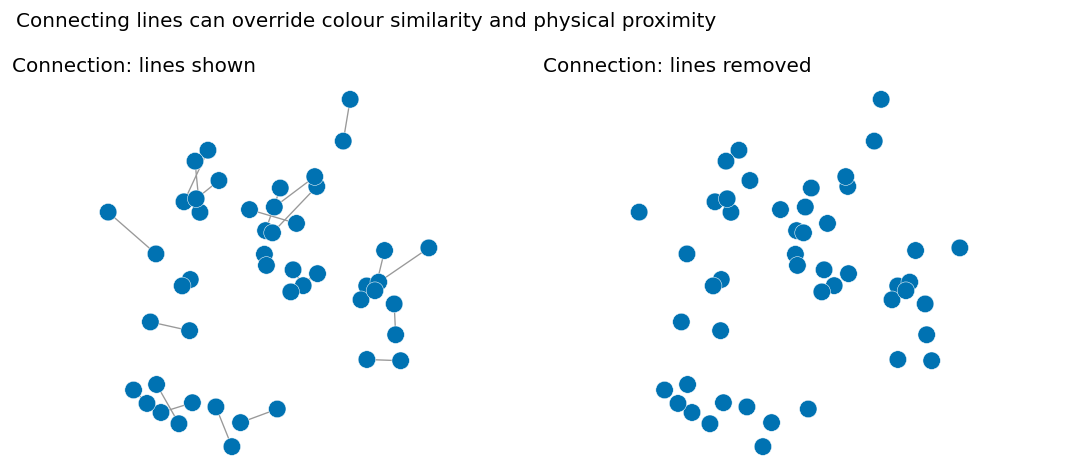

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
draw_gestalt_panel(axes[0], "connection", draw_connectors=True)
axes[0].set_title("Connection: lines shown", loc="left")
draw_gestalt_panel(axes[1], "connection", draw_connectors=False)
axes[1].set_title("Connection: lines removed", loc="left")
fig.suptitle("Connecting lines can override colour similarity and physical proximity", x=.02, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "task2_connection_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

2.4 Use proximity in a real chart 

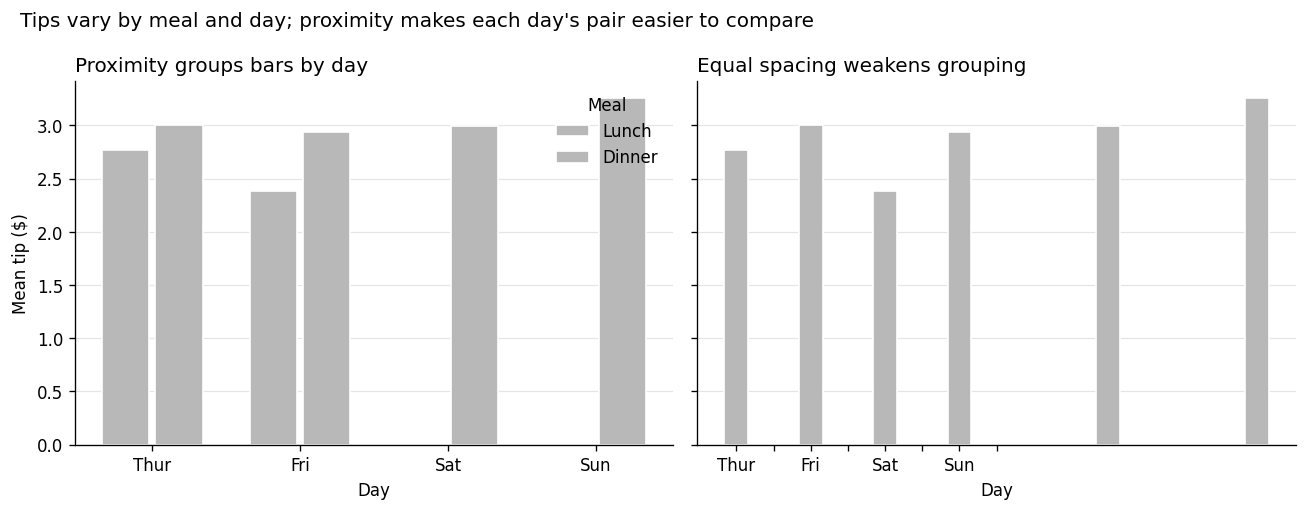

In [5]:
tips = pd.read_csv(DATA / "tips.csv")
tips["day"] = pd.Categorical(tips["day"], categories=["Thur","Fri","Sat","Sun"], ordered=True)
tips["time"] = pd.Categorical(tips["time"], categories=["Lunch","Dinner"], ordered=True)
summary = tips.groupby(["day","time"], observed=True).tip.mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
x = np.arange(len(summary.index))
width = .32
# Proximity version: lunch/dinner bars are close within each day, with a larger between-day gap.
for ax, grouped in zip(axes, [True, False]):
    if grouped:
        offsets = [-.18,.18]
        positions = [x+offsets[0], x+offsets[1]]
        subtitle = "Proximity groups bars by day"
    else:
        # Equal-spaced bars weaken the within-day grouping cue.
        positions = [np.arange(0, len(summary.index)*2, 2), np.arange(1, len(summary.index)*2, 2)]
        subtitle = "Equal spacing weakens grouping"
    for time_label, pos in zip(["Lunch","Dinner"], positions):
        vals = summary[time_label].to_numpy()
        ax.bar(pos, vals, width=width, color=GREY, edgecolor="white", label=time_label)
    ax.set_xticks(x if grouped else np.arange(len(summary.index)*2)/2)
    ax.set_xticklabels(summary.index if grouped else ["Thur","", "Fri","", "Sat","", "Sun",""])
    ax.set_title(subtitle, loc="left")
    ax.set_xlabel("Day"); ax.grid(axis="y", color="#E5E5E5", linewidth=.7); ax.set_axisbelow(True)
axes[0].set_ylabel("Mean tip ($)")
axes[0].legend(frameon=False, title="Meal")
fig.suptitle("Tips vary by meal and day; proximity makes each day's pair easier to compare", x=.02, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "task2_tips_proximity.png", dpi=300, bbox_inches="tight")
plt.show()

### 2.5 Where the six principles appear in charts

- **Proximity:** grouped bars placed close within each category communicate a shared category.
- **Similarity:** the same marker shape for one series across a line chart signals that the marks belong together.
- **Enclosure:** a shaded band around a recession period separates that time span from the rest of a timeline.
- **Closure:** a lightly outlined region with a small gap can still be perceived as one highlighted area.
- **Continuity:** a line joining monthly observations encourages the eye to follow the trend across time.
- **Connection:** a line between paired observations signals a relationship more strongly than colour alone.

**Why direct labelling is cheaper than a legend:** Direct labels place the category name beside the data, using spatial proximity. With a legend, a reader must remember the colour-to-category mapping, shift attention back and forth, and match the marks. Direct labelling reduces that extraneous working-memory burden and leaves more capacity for understanding the data.

---
# Task 3 — Cognitive Load and the Data-Ink Ratio


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Wedge, Circle
from IPython.display import display, Markdown, clear_output
DATA = Path("data")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
GREY = "#B8B8B8"
DARK_GREY = "#666666"
ACCENT = "#D55E00"
BLUE = "#0072B2"

crashes = pd.read_csv(DATA / "car_crashes.csv")
tips = pd.read_csv(DATA / "tips.csv")
print("car_crashes:", crashes.shape, "| missing values:", int(crashes.isna().sum().sum()))
print("tips:", tips.shape, "| missing values:", int(tips.isna().sum().sum()))

car_crashes: (51, 8) | missing values: 0
tips: (244, 7) | missing values: 0


### 3.1 Deliberately overloaded chart

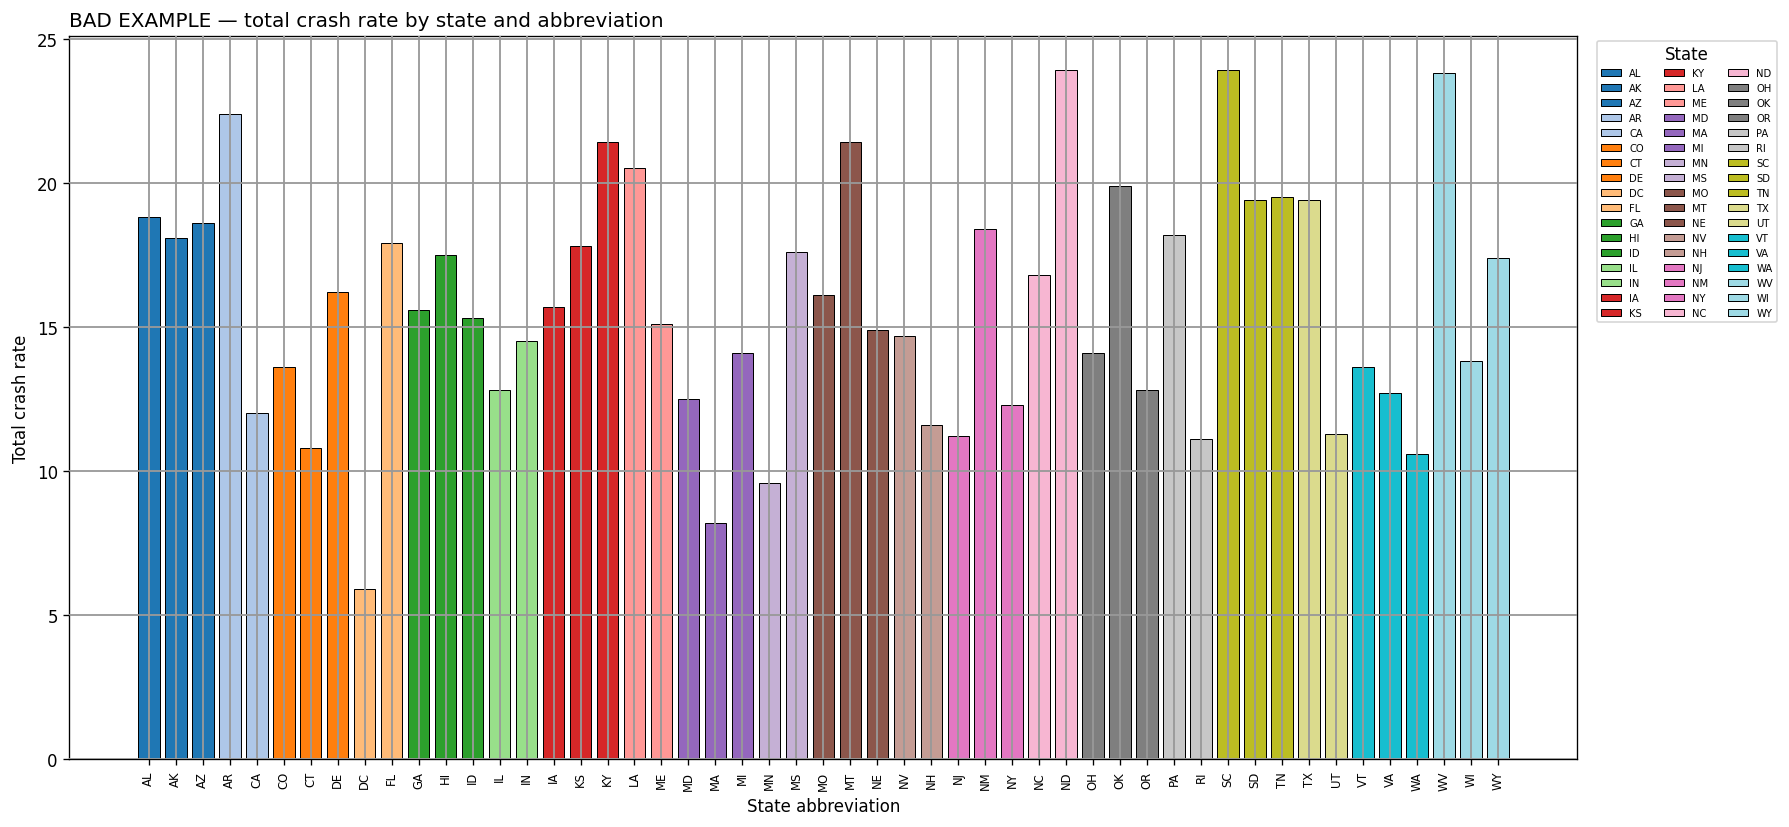

In [2]:
fig, ax = plt.subplots(figsize=(15, 7))
d = crashes.reset_index(drop=True)
palette = plt.cm.tab20(np.linspace(0, 1, len(d)))
bars = ax.bar(d.abbrev, d.total, color=palette, edgecolor="black", linewidth=.6)
ax.set_title("BAD EXAMPLE — total crash rate by state and abbreviation", loc="left")
ax.set_xlabel("State abbreviation"); ax.set_ylabel("Total crash rate")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.grid(axis="both", color="#999999", linewidth=1.1)
ax.set_axisbelow(False)
# 51 legend entries intentionally create extraneous decoding work.
ax.legend(bars, d.abbrev, title="State", ncol=3, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=6, frameon=True)
for side in ("top","right","left","bottom"): ax.spines[side].set_visible(True)
fig.tight_layout()
fig.savefig(FIG / "task3_bad_overloaded.png", dpi=300, bbox_inches="tight")
plt.show()

### 3.2 Remove clutter in five steps

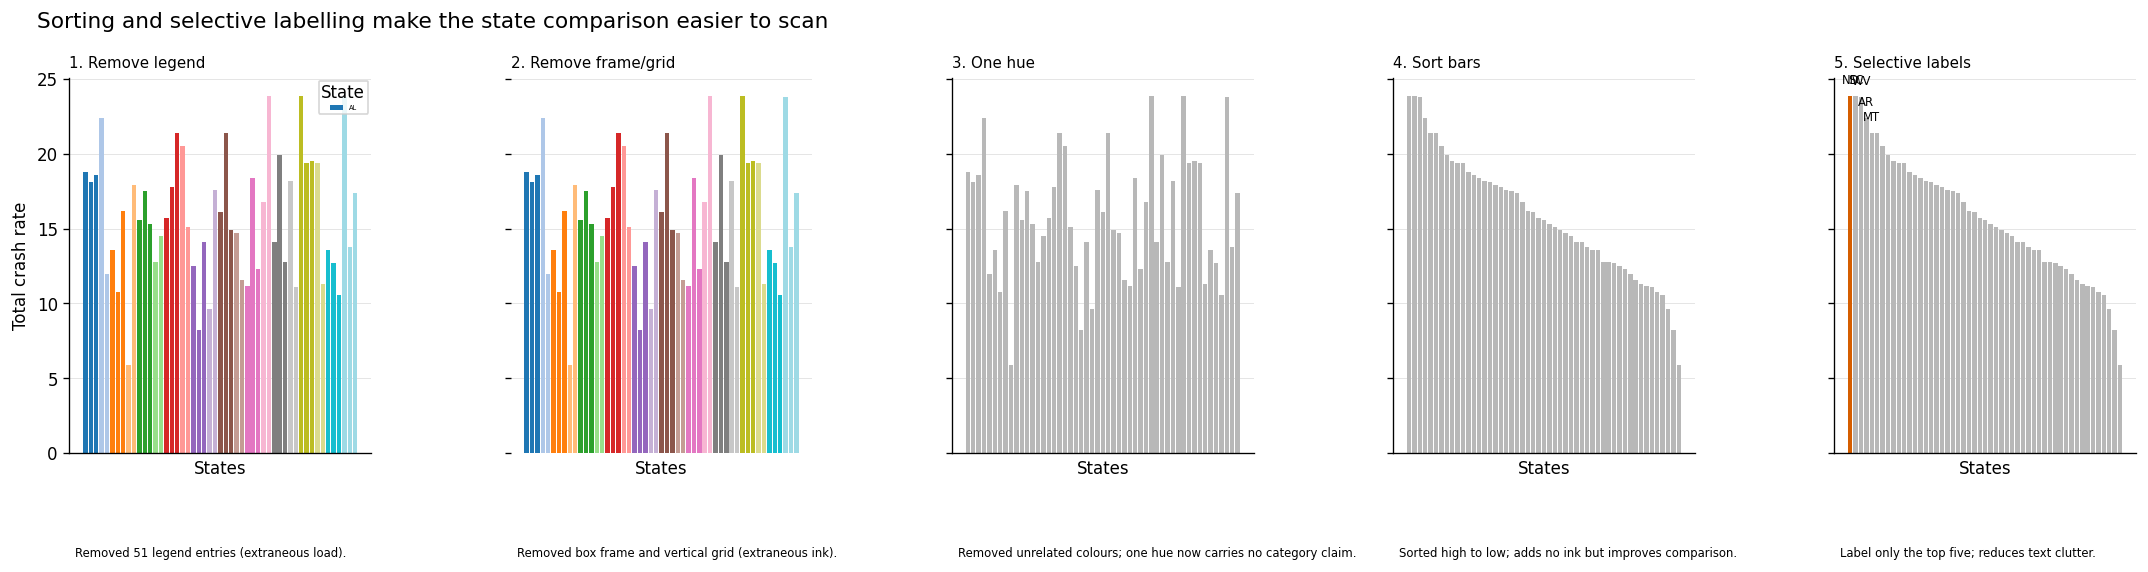

In [3]:
d = crashes.sort_values("total", ascending=False).reset_index(drop=True)
fig, axes = plt.subplots(1, 5, figsize=(18, 5), sharey=True)
steps = [
    ("1. Remove legend", "Removed 51 legend entries (extraneous load).", True, True, True, False),
    ("2. Remove frame/grid", "Removed box frame and vertical grid (extraneous ink).", False, False, True, False),
    ("3. One hue", "Removed unrelated colours; one hue now carries no category claim.", False, False, False, False),
    ("4. Sort bars", "Sorted high to low; adds no ink but improves comparison.", False, False, False, True),
    ("5. Selective labels", "Label only the top five; reduces text clutter.", False, False, False, True),
]
for i, (title, note, legend, frame, multicolour, sorted_flag) in enumerate(steps):
    ax = axes[i]
    dd = crashes.copy()
    if sorted_flag: dd = dd.sort_values("total", ascending=False)
    if i == 4:
        colors = [ACCENT if j == 0 else GREY for j in range(len(dd))]
    elif multicolour:
        colors = plt.cm.tab20(np.linspace(0,1,len(dd)))
    else:
        colors = [GREY] * len(dd)
    ax.bar(np.arange(len(dd)), dd.total, color=colors, width=.82)
    ax.set_title(title, loc="left", fontsize=9)
    ax.set_xlabel("States")
    ax.set_xticks([])
    ax.grid(axis="y", color="#E5E5E5", linewidth=.6); ax.set_axisbelow(True)
    if i == 0:
        # keep legend only in step 1 to show it being removed after this stage
        ax.legend([str(x) for x in crashes.abbrev], title="State", ncol=2, fontsize=4, frameon=True, loc="upper right")
    if i == 1:
        for side in ("top","right","left","bottom"): ax.spines[side].set_visible(False)
    if i == 4:
        top = dd.head(5)
        for rank, row in enumerate(top.itertuples()):
            ax.text(rank, row.total + .6, row.abbrev, ha="center", va="bottom", fontsize=7)
    ax.text(.02, -.25, note, transform=ax.transAxes, fontsize=7, wrap=True, va="top")
axes[0].set_ylabel("Total crash rate")
fig.suptitle("Sorting and selective labelling make the state comparison easier to scan", x=.02, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(FIG / "task3_five_step_cleanup.png", dpi=300, bbox_inches="tight")
plt.show()

**Why this chart:** The five panels apply the cleanup in sequence while keeping the same 51 observations and a zero baseline. Grey is context; in the final panel only the single highest state is highlighted in orange, matching the title's emphasis on making the ranking easier to scan. Sorting is the highest-value edit because it adds no marks at all, yet puts the largest values together. The fifth panel labels only the top five to avoid 51 competing text labels. No rows or outliers were excluded.

### 3.3 Chunk the comparison and state the cost

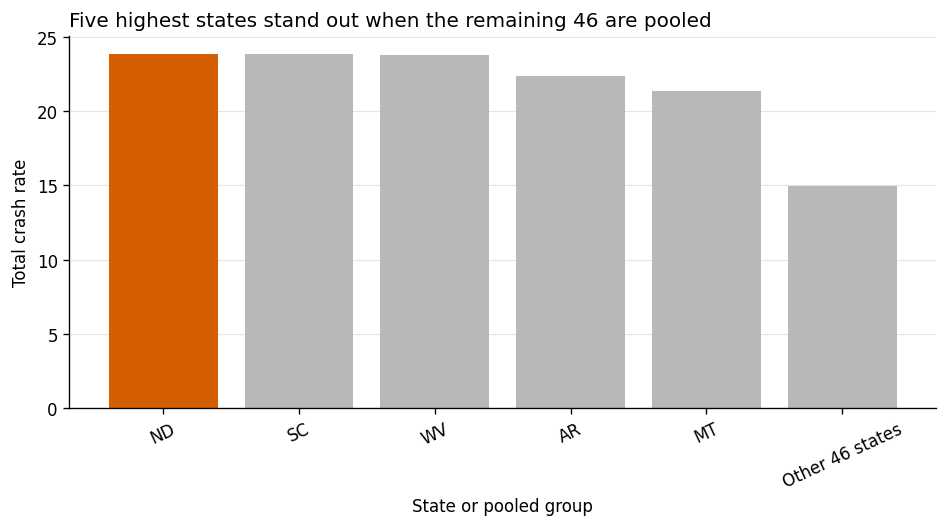

Other 46 states shown as their mean; this aggregation hides variation within that group.


In [4]:
ranked = crashes.sort_values("total", ascending=False).reset_index(drop=True)
top5 = ranked.head(5).copy()
other_mean = ranked.iloc[5:].total.mean()
chunked = pd.DataFrame({"group": list(top5.abbrev) + ["Other 46 states"],
                        "total": list(top5.total) + [other_mean]})
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [ACCENT] + [GREY]*5
ax.bar(chunked.group, chunked.total, color=colors)
ax.set_title("Five highest states stand out when the remaining 46 are pooled", loc="left")
ax.set_xlabel("State or pooled group"); ax.set_ylabel("Total crash rate")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", color="#E5E5E5", linewidth=.7); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG / "task3_chunked_top5.png", dpi=300, bbox_inches="tight"); plt.show()
print("Other 46 states shown as their mean; this aggregation hides variation within that group.")

### 3.4 Over-strip the chart

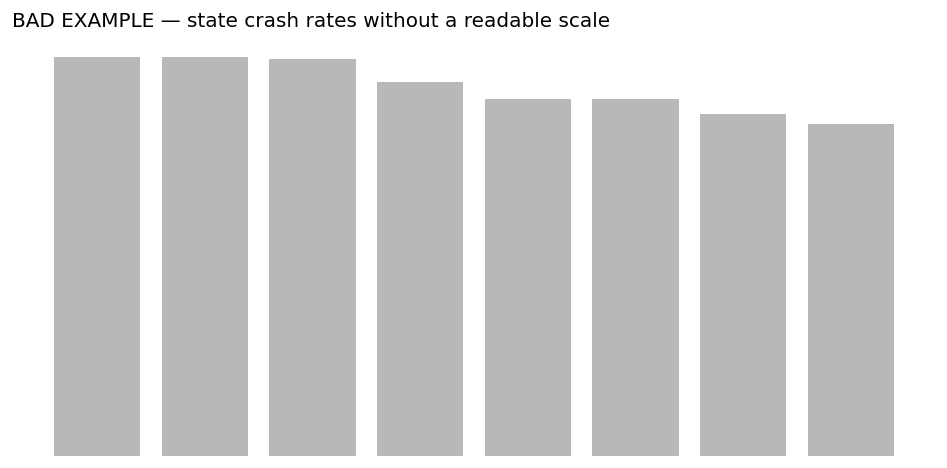

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ranked.head(8).abbrev, ranked.head(8).total, color=GREY)
ax.set_title("BAD EXAMPLE — state crash rates without a readable scale", loc="left")
ax.set_xticks([]); ax.set_yticks([])
for side in ("top","right","left","bottom"): ax.spines[side].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "task3_overstripped_bad.png", dpi=300, bbox_inches="tight"); plt.show()

3.5 Add ink when it reduces mental arithmetic 

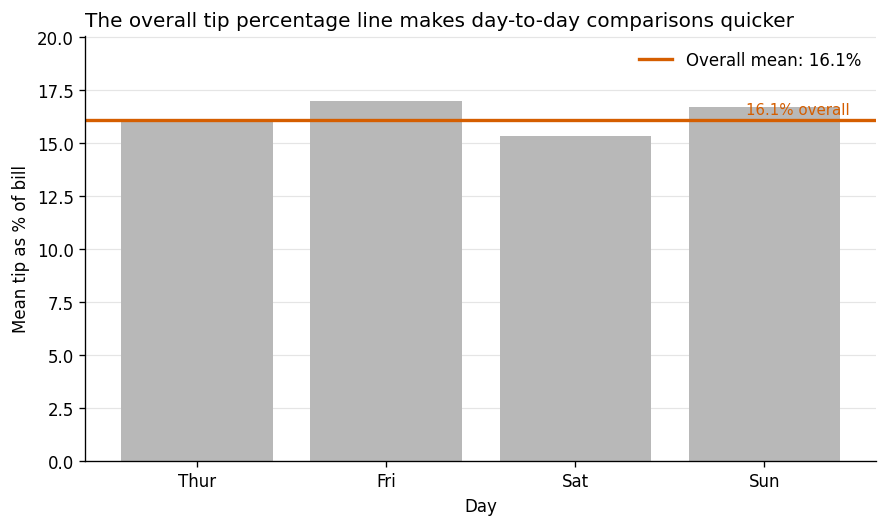

In [6]:
tips["tip_pct"] = 100 * tips.tip / tips.total_bill
by_day = tips.groupby("day", observed=True).tip_pct.mean().reindex(["Thur","Fri","Sat","Sun"])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(by_day.index.astype(str), by_day.values, color=GREY)
overall = tips.tip_pct.mean()
ax.axhline(overall, color=ACCENT, linewidth=2, label=f"Overall mean: {overall:.1f}%")
ax.text(3.45, overall + .15, f"{overall:.1f}% overall", color=ACCENT, ha="right", va="bottom", fontsize=9)
ax.set_title("The overall tip percentage line makes day-to-day comparisons quicker", loc="left")
ax.set_xlabel("Day"); ax.set_ylabel("Mean tip as % of bill")
ax.set_ylim(0, max(by_day.max(), overall)*1.18)
ax.grid(axis="y", color="#E5E5E5", linewidth=.7); ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "task3_reference_line_tips.png", dpi=300, bbox_inches="tight"); plt.show()

 Task 4  Channel Effectiveness


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Wedge, Circle
from IPython.display import display, Markdown, clear_output
DATA = Path("data")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
GREY = "#B8B8B8"
DARK_GREY = "#666666"
ACCENT = "#D55E00"
BLUE = "#0072B2"

trials = pd.read_csv(DATA / "channel_trials.csv")
iris = pd.read_csv(DATA / "iris.csv")
print("Trials:", trials.shape, "| blank estimates:", int(trials.reader_estimate.isna().sum()))
display(trials.groupby("channel").agg(trials=("trial","count"), ratios=("true_ratio","nunique")))

Trials: (30, 7) | blank estimates: 30


,trials,ratios
channel,,
angle,6,6
area,6,6
colour,6,6
length,6,6
position,6,6


### 4.1 Draw one pair using each channel

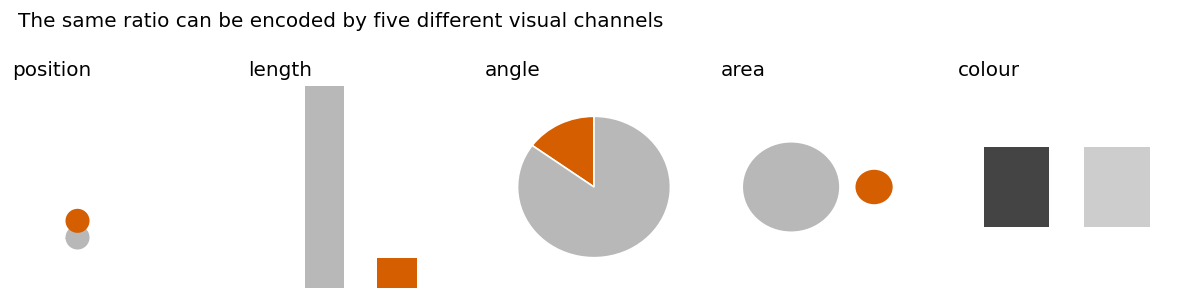

In [2]:
def draw_channel_trial(row, ax):
    """Encode a pair without numeric labels or tick values."""
    channel = str(row.channel).lower()
    large, small = float(row.value_large), float(row.value_small)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xticks([]); ax.set_yticks([])
    for side in ("top","right","left","bottom"): ax.spines[side].set_visible(False)
    if channel == "position":
        ax.scatter([.25,.25], [.25,.25], s=1)  # invisible anchor; axis range is fixed
        ax.scatter([.3,.3], [.25,.25 + .55*(small/large)], s=180, c=[GREY,ACCENT])
    elif channel == "length":
        ax.bar([.35,.68], [large/large, small/large], width=.18, color=[GREY,ACCENT], bottom=0)
    elif channel == "angle":
        ax.add_patch(Wedge((.5,.5), .35, 90, 90+360*(small/large), facecolor=ACCENT, edgecolor="white"))
        ax.add_patch(Wedge((.5,.5), .35, 90+360*(small/large), 450, facecolor=GREY, edgecolor="white"))
    elif channel == "area":
        ax.add_patch(Circle((.32,.5), .22, facecolor=GREY, edgecolor="none"))
        ax.add_patch(Circle((.70,.5), .22*np.sqrt(small/large), facecolor=ACCENT, edgecolor="none"))
    elif channel == "colour":
        # Ordered sequential lightness: the smaller value is lighter/darker in a monotonic grey ramp.
        ax.add_patch(Rectangle((.12,.3), .3,.4, facecolor="#444444", edgecolor="none"))
        light = 0.25 + .65*(1-small/large)
        shade = str(float(np.clip(light,0,1)))
        ax.add_patch(Rectangle((.58,.3), .3,.4, facecolor=shade, edgecolor="none"))
    else:
        raise ValueError(f"Unknown channel: {channel}")
    ax.set_title(channel, loc="left")

fig, axes = plt.subplots(1, 5, figsize=(10, 2.5))
for ax, channel in zip(axes, ["position","length","angle","area","colour"]):
    row = trials[trials.channel.eq(channel)].iloc[0]
    draw_channel_trial(row, ax)
fig.suptitle("The same ratio can be encoded by five different visual channels", x=.02, ha="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "task4_channel_examples.png", dpi=300, bbox_inches="tight"); plt.show()

### 4.2 Run 30 trials with a real participant

In [3]:
def run_channel_experiment(participant="a classmate", seed=42):
    """Present all 30 trials in shuffled order and save estimates from a real reader."""
    rng = np.random.default_rng(seed)
    order = trials.sample(frac=1, random_state=seed).reset_index(drop=True)
    records = []
    fig, ax = plt.subplots(figsize=(3.2, 3.2))
    for i, row in enumerate(order.itertuples(index=False), start=1):
        clear_output(wait=True)
        print(f"Participant: {participant} | Trial {i}/{len(order)}")
        ax.clear(); draw_channel_trial(row, ax); display(fig)
        answer = input("The smaller one is what percentage of the larger? Enter a number from 0 to 100: ").strip()
        try:
            estimate = float(answer)
            if not 0 <= estimate <= 100: raise ValueError
        except ValueError:
            print("Invalid estimate. Rerun this trial with a value from 0 to 100.")
            raise
        records.append({"participant": participant, "trial": row.trial, "channel": row.channel,
                        "true_ratio": row.true_ratio, "value_large": row.value_large,
                        "value_small": row.value_small, "reader_estimate": estimate,
                        "absolute_error": abs(estimate/100 - row.true_ratio)})
    plt.close(fig)
    result = pd.DataFrame(records)
    result.to_csv("channel_results.csv", index=False)
    clear_output(wait=True)
    print("Saved genuine estimates to channel_results.csv")
    return result

# Uncomment and run with a real participant:
# channel_results = run_channel_experiment(participant="a classmate")

### 4.3 Rank the channels by mean absolute error

In [4]:
def analyse_channel_results(path="channel_results.csv"):
    r = pd.read_csv(path)
    r["absolute_error"] = (r.reader_estimate / 100 - r.true_ratio).abs()
    ranking = r.groupby("channel", as_index=False).absolute_error.mean().sort_values("absolute_error")
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.bar(ranking.channel, ranking.absolute_error, color=GREY)
    best = ranking.index[0]
    # One pop-out: lowest observed error channel.
    order = ranking.reset_index(drop=True)
    for i, row in enumerate(order.itertuples()):
        if i == 0:
            ax.patches[i].set_facecolor(ACCENT)
    ax.set_title("The lowest-error channel is easiest for this reader to judge", loc="left")
    ax.set_xlabel("Visual channel"); ax.set_ylabel("Mean absolute error (ratio units)")
    ax.set_ylim(0, max(ranking.absolute_error.max()*1.15, .01))
    ax.grid(axis="y", color="#E5E5E5", linewidth=.7); ax.set_axisbelow(True)
    fig.tight_layout(); fig.savefig(FIG / "task4_channel_error_ranking.png", dpi=300, bbox_inches="tight"); plt.show()
    display(ranking.reset_index(drop=True))
    print("No trials excluded unless their estimates are missing; document any exclusions here.")
    return ranking

# After running the real experiment:
# channel_ranking = analyse_channel_results()

**Interpretation template:** compare the measured order with the reference order **position > length > angle > area > volume > colour**. The supplied data can compare five channels; it cannot test volume. Report any disagreement without changing estimates or removing inconvenient trials. The bar chart uses a zero baseline, and its one coloured bar highlights the lowest observed mean error. The channel ranking is only available after genuine estimates are recorded.

### 4.4 Apply a high- and low-ranking channel to `iris.csv`

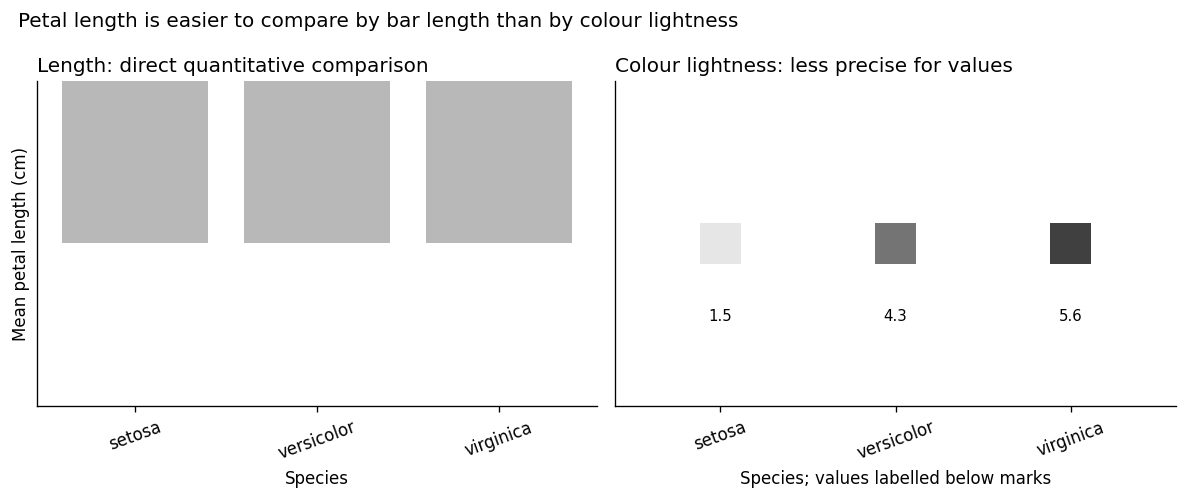

In [5]:
iris = pd.read_csv(DATA / "iris.csv")
species = list(iris.species.unique())
summary = iris.groupby("species").petal_length.mean().reindex(species)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
# High-ranking channel: length from a common zero baseline.
axes[0].bar(summary.index, summary.values, color=GREY)
axes[0].set_title("Length: direct quantitative comparison", loc="left")
axes[0].set_ylabel("Mean petal length (cm)")
axes[0].set_xlabel("Species")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", color="#E5E5E5", linewidth=.7); axes[0].set_axisbelow(True)
# Low-ranking channel: ordered lightness. Values are also printed to avoid colour-only decoding.
norm = (summary - summary.min()) / (summary.max() - summary.min())
for i, (name, value) in enumerate(summary.items()):
    shade = str(float(0.25 + .65*(1-norm[name])))
    axes[1].scatter(i, 0, s=600, c=shade, marker="s", edgecolors="none")
    axes[1].text(i, -.12, f"{value:.1f}", ha="center", va="top", fontsize=9)
axes[1].set_xlim(-.6, len(summary)-.4); axes[1].set_ylim(-.3,.3)
axes[1].set_xticks(range(len(summary))); axes[1].set_xticklabels(summary.index, rotation=20)
axes[1].set_yticks([]); axes[1].set_title("Colour lightness: less precise for values", loc="left")
axes[1].set_xlabel("Species; values labelled below marks")
fig.suptitle("Petal length is easier to compare by bar length than by colour lightness", x=.02, ha="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "task4_iris_channel_comparison.png", dpi=300, bbox_inches="tight"); plt.show()

**Why this chart:** The left panel encodes mean petal length using bar length and position against a zero baseline, both high-ranking channels for quantitative data. The right panel uses ordered colour lightness as a deliberately weaker quantitative channel, but prints the actual values so meaning is not carried by colour alone. The colour is a sequential grayscale ramp, not a rainbow. Similarity groups each species' mark, and position keeps category locations stable. All 150 iris rows are used to compute species means; none are excluded.

### 4.5 What this experiment can and cannot support

Thirty judgments from one reader can illustrate that different channels produce different errors for that person and these six ratios. It cannot estimate population-level effects, establish statistical significance, or reliably settle close rankings. The published Cleveland–McGill ordering remains useful because it comes from a broader controlled body of evidence, while a tiny personal experiment is sensitive to attention, visual acuity, practice, display size, and random error. Record the reader and conditions, and avoid presenting this class exercise as a generalizable study.

---
# Task 5 — Capstone — Redesign for the Human Visual System


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Wedge, Circle
from IPython.display import display, Markdown, clear_output
DATA = Path("data")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
GREY = "#B8B8B8"
DARK_GREY = "#666666"
ACCENT = "#D55E00"
BLUE = "#0072B2"

gap = pd.read_csv(DATA / "gapminder.csv")
print("Rows:", len(gap), "| countries:", gap.country.nunique(), "| years:", gap.year.nunique())
print("Missing values:", int(gap.isna().sum().sum()))
display(gap.head())

Rows: 1704 | countries: 142 | years: 12
Missing values: 0


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106


### 5.1 Bad example and question

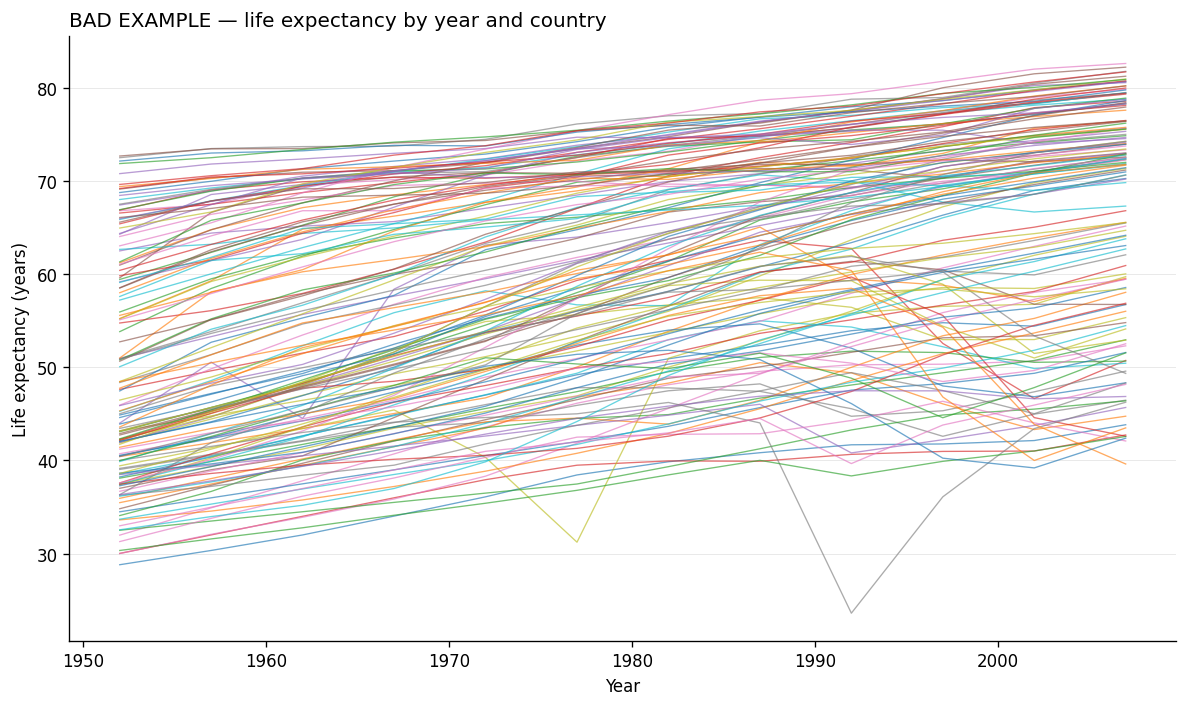

In [2]:
fig, ax = plt.subplots(figsize=(10, 6))
for country, g in gap.groupby("country"):
    g = g.sort_values("year")
    ax.plot(g.year, g.lifeExp, linewidth=.8, alpha=.65)
ax.set_title("BAD EXAMPLE — life expectancy by year and country", loc="left")
ax.set_xlabel("Year"); ax.set_ylabel("Life expectancy (years)")
ax.grid(axis="y", color="#E5E5E5", linewidth=.5)
fig.tight_layout(); fig.savefig(FIG / "task5_bad_spaghetti.png", dpi=300, bbox_inches="tight"); plt.show()

**Question the reader should answer:** How has life expectancy changed over time, and which country should they inspect? The spaghetti plot is intentionally labelled `BAD EXAMPLE`. With 142 country lines, colour/overlap and continuity compete, no one country is the clear message, and the viewer must track many paths. All 1,704 rows are included; no countries, years, or outliers were excluded.

### 5.2 Perception audit before redesign

| Audit dimension | Original spaghetti plot |
|---|---|
| Preattentive | Position encodes year and life expectancy; line continuity is useful, but 142 overlapping trajectories overwhelm it. |
| Pop-out | Nothing reliably pops out; the title does not nominate a specific country or finding. |
| Gestalt | Continuity connects each country's yearly values, but crossing lines make paths hard to follow. |
| Cognitive load | Intrinsic: comparing country trajectories. Extraneous: overlapping lines, repeated legend-like paths, grid clutter. Germane: year axis and life-expectancy scale. |
| Channels | x/y position encode quantitative variables (high-ranking); line continuity helps trace time. Country identity is not reliably distinguished. |
| Working memory | Potentially 142 trajectories; far beyond roughly four chunks at once. |

### 5.3 Redesign: one message, context in grey, one pop-out

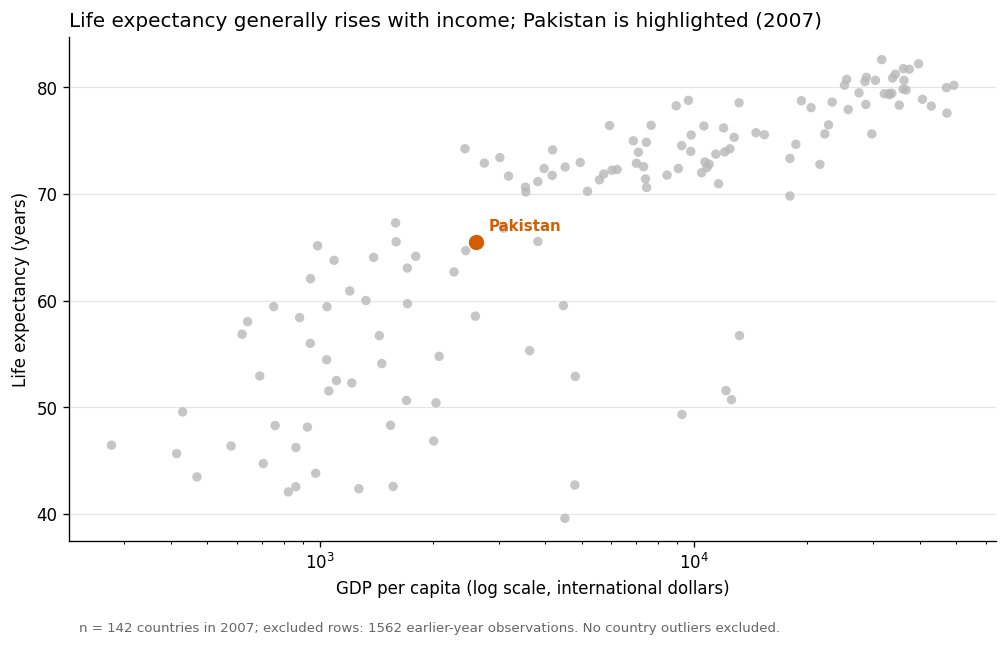

In [3]:
# Use the latest year available in the supplied data and a single, explicitly named country.
latest_year = int(gap.year.max())
latest = gap[gap.year.eq(latest_year)].copy()
selected_country = "Pakistan"
selected = latest[latest.country.eq(selected_country)]
if selected.empty:
    selected_country = str(latest.sort_values("lifeExp", ascending=False).iloc[0].country)
    selected = latest[latest.country.eq(selected_country)]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(latest.gdpPercap, latest.lifeExp, s=32, color=GREY, alpha=.8, edgecolors="none", label="Other countries")
row = selected.iloc[0]
ax.scatter([row.gdpPercap], [row.lifeExp], s=100, color=ACCENT, edgecolors="white", linewidths=.8, zorder=3)
ax.annotate(selected_country, (row.gdpPercap, row.lifeExp), xytext=(8, 7), textcoords="offset points",
            fontsize=9, color=ACCENT, weight="bold")
ax.set_xscale("log")
ax.set_title(f"Life expectancy generally rises with income; {selected_country} is highlighted ({latest_year})", loc="left")
ax.set_xlabel("GDP per capita (log scale, international dollars)")
ax.set_ylabel("Life expectancy (years)")
ax.grid(axis="y", color="#E5E5E5", linewidth=.7); ax.set_axisbelow(True)
ax.text(.01, -.18, f"n = {len(latest)} countries in {latest_year}; excluded rows: {len(gap)-len(latest)} earlier-year observations. No country outliers excluded.",
        transform=ax.transAxes, fontsize=8, color=DARK_GREY)
fig.tight_layout()
fig.savefig(FIG / "perception_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

**Why this chart:** A scatterplot is appropriate for the relationship between two quantitative variables. Both are encoded by position, a high-ranking channel; the x-axis is logarithmic because income spans a wide range, and the axis states that transformation. The title states the finding rather than just naming the variables. Grey context preserves the overall distribution while the single orange point and its direct label create exactly one pop-out. The Gestalt principle is **similarity**: the grey marks are read as a shared context group, with one exception called out. Country identity is not encoded by colour alone because the selected country is also directly labelled. The figure includes `n` and explicitly reports that only the latest-year slice is shown; no country outliers are excluded.

### 5.4 Before-and-after perception audit

| Audit dimension | Original spaghetti plot | Redesign |
|---|---|---|
| Preattentive | Position and continuity are present but crowded. | Position carries both quantitative variables; one orange hue marks the selected country. |
| Pop-out | No dependable pop-out. | Exactly one highlighted point, labelled directly, matches the title's focus. |
| Gestalt | Continuity joins every country's series, but paths cross. | Similarity groups all grey countries as context; the one labelled point is the exception. |
| Cognitive load | Intrinsic: country trends; extraneous: 142 overlapping paths; germane: axes and trajectories. | Intrinsic: income–life expectancy relationship; extraneous: reduced through filtering to one year; germane: axes, log-scale label, direct country label. |
| Channels | Position plus line continuity; country identity hard to trace. | Position on x and y, both high-ranking for quantitative data; colour reinforces rather than carries identity alone. |
| Working memory | Up to 142 trajectories. | Two axes plus one highlighted country/context cloud—approximately three chunks. |

### 5.5 Human test — required before submission

Show the redesign (not the original) to someone who has not seen the data and ask: **“In one sentence, what does this chart show?”**

Record the exact sentence here after the test:

> **Participant:** [first name or “a classmate”]  
> **Verbatim response:** “[paste their exact sentence here]”  
> **Did it match the title?** [yes/no, with a short explanation]

Do not submit an invented quotation. If the reader does not mention the positive relationship or mistakes the highlighted country for the overall trend, revise the title/annotation or add a concise note. A real human response is required to complete this task.

### 5.6 What the redesign makes harder to see

The redesign hides changes over time and country-specific trajectories because it shows only the latest year. That is a deliberate trade-off: it makes the cross-country relationship and one country easier to interpret, but it cannot answer how a country's life expectancy evolved across the 12-year period.

### Export and self-audit

- [x] Object-oriented Matplotlib API (`fig, ax = plt.subplots()` and `ax` methods).
- [x] The redesigned chart has one pop-out; context is grey and the message is one strong colour.
- [x] Gestalt principle named: similarity.
- [x] Main quantitative variables use position.
- [x] Colour is reinforced with a direct label, not used alone.
- [x] `n` and excluded earlier-year rows are declared on the figure.
- [x] The redesigned figure is saved at 300 DPI as `figures/perception_redesign.png`.
- [ ] Real reader's verbatim sentence recorded.